
# House Price Prediction Project

## Models Used
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- KNN Regressor

In [ ]:

# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.neighbors import KNeighborsRegressor


from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings('ignore')


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving HousingPrices-Amsterdam-August-2021.csv to HousingPrices-Amsterdam-August-2021.csv


In [ ]:

# Load Dataset

df = pd.read_csv('/content/HousingPrices-Amsterdam-August-2021.csv')

df.head()


,Unnamed: 0,Address,Zip,Price,Area,Room,Lon,Lat
0,1,"Blasiusstraat 8 2, Amsterdam",1091 CR,685000.0,64,3,4.907736,52.356157
1,2,"Kromme Leimuidenstraat 13 H, Amsterdam",1059 EL,475000.0,60,3,4.850476,52.348586
2,3,"Zaaiersweg 11 A, Amsterdam",1097 SM,850000.0,109,4,4.944774,52.343782
3,4,"Tenerifestraat 40, Amsterdam",1060 TH,580000.0,128,6,4.789928,52.343712
4,5,"Winterjanpad 21, Amsterdam",1036 KN,720000.0,138,5,4.902503,52.410538


In [ ]:

# Shape

df.shape


(924, 8)

In [ ]:

# Information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 924 entries, 0 to 923
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  924 non-null    int64  
 1   Address     924 non-null    object 
 2   Zip         924 non-null    object 
 3   Price       920 non-null    float64
 4   Area        924 non-null    int64  
 5   Room        924 non-null    int64  
 6   Lon         924 non-null    float64
 7   Lat         924 non-null    float64
dtypes: float64(3), int64(3), object(2)
memory usage: 57.9+ KB


In [ ]:

# Statistical Summary

df.describe()


,Unnamed: 0,Price,Area,Room,Lon,Lat
count,924.000000,9.200000e+02,924.000000,924.000000,924.000000,924.000000
mean,462.500000,6.220654e+05,95.952381,3.571429,4.888605,52.363326
std,266.880123,5.389942e+05,57.447436,1.592332,0.053140,0.024028
min,1.000000,1.750000e+05,21.000000,1.000000,4.644819,52.291519
25%,231.750000,3.500000e+05,60.750000,3.000000,4.855834,52.352077
50%,462.500000,4.670000e+05,83.000000,3.000000,4.886818,52.364631
75%,693.250000,7.000000e+05,113.000000,4.000000,4.922337,52.377598
max,924.000000,5.950000e+06,623.000000,14.000000,5.029122,52.423805


In [ ]:

# Null Values

df.isnull().sum()


,0
Unnamed: 0,0
Address,0
Zip,0
Price,4
Area,0
Room,0
Lon,0
Lat,0


In [ ]:

# Duplicate Values

df.duplicated().sum()


np.int64(0)

In [ ]:

# Remove Duplicate Values

df = df.drop_duplicates()

df.shape


(924, 8)


# EDA


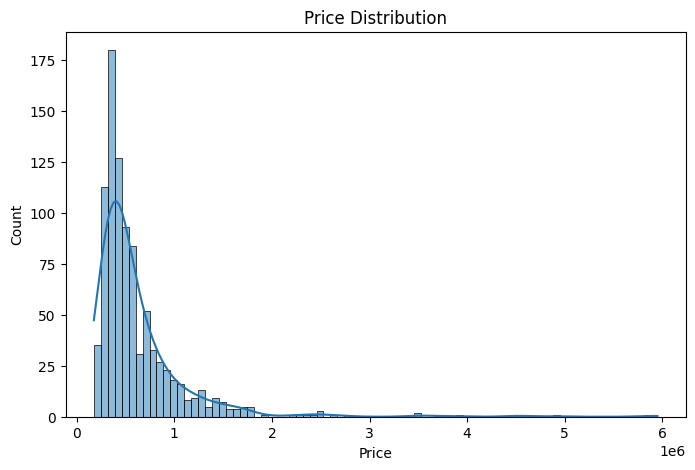

In [ ]:
# Price Distribution

plt.figure(figsize=(8,5))

sns.histplot(df['Price'], kde=True)

plt.title('Price Distribution')

plt.show()


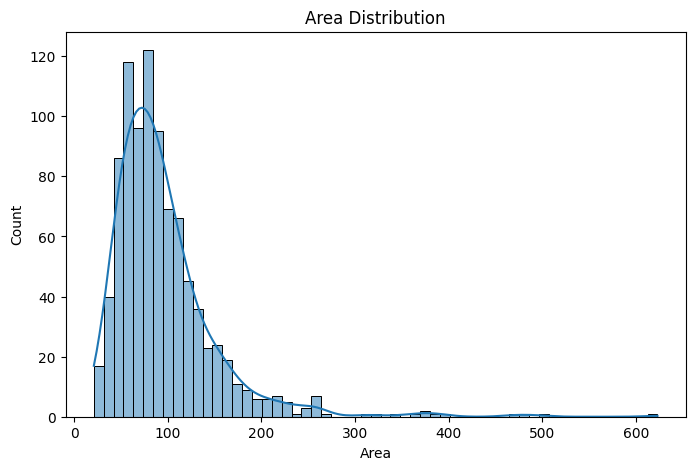

In [ ]:
# Area Distribution

plt.figure(figsize=(8,5))

sns.histplot(df['Area'], kde=True)

plt.title('Area Distribution')

plt.show()


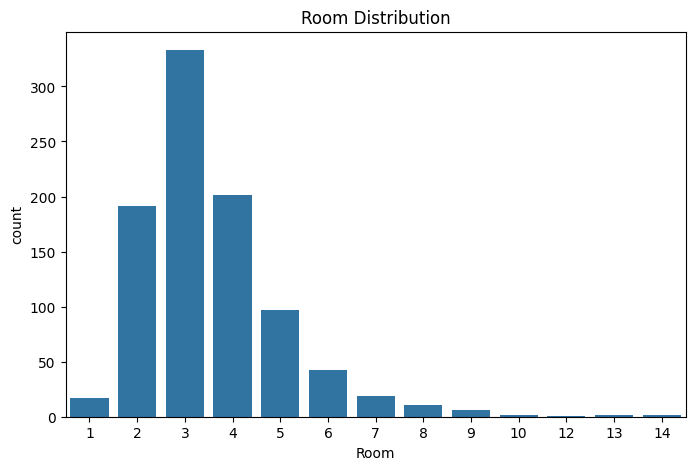

In [ ]:
# Room Distribution

plt.figure(figsize=(8,5))

sns.countplot(x=df['Room'])

plt.title('Room Distribution')

plt.show()


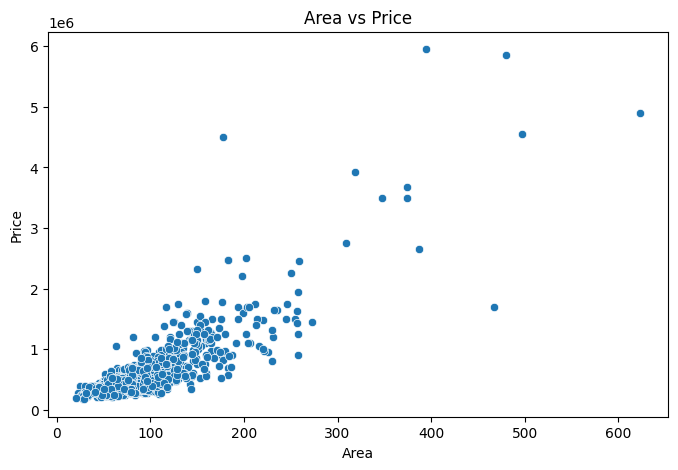

In [ ]:
# Area vs Price

plt.figure(figsize=(8,5))

sns.scatterplot(x=df['Area'], y=df['Price'])

plt.title('Area vs Price')

plt.show()


In [ ]:
df.head(3)

,Unnamed: 0,Address,Zip,Price,Area,Room,Lon,Lat
0,1,"Blasiusstraat 8 2, Amsterdam",1091 CR,685000.0,64,3,4.907736,52.356157
1,2,"Kromme Leimuidenstraat 13 H, Amsterdam",1059 EL,475000.0,60,3,4.850476,52.348586
2,3,"Zaaiersweg 11 A, Amsterdam",1097 SM,850000.0,109,4,4.944774,52.343782


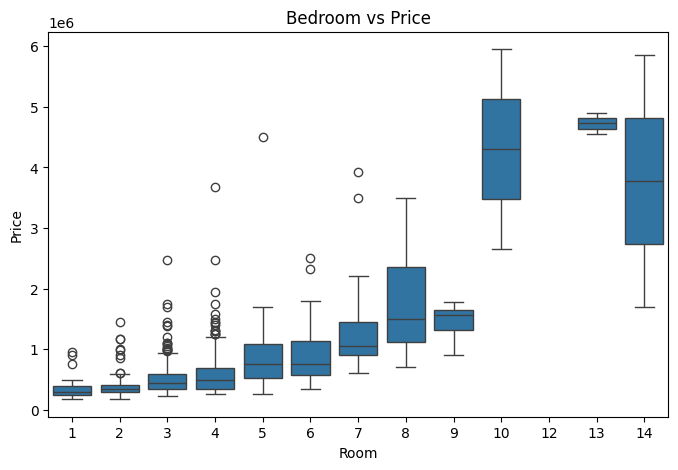

In [ ]:
# Bedroom vs Price

plt.figure(figsize=(8,5))

sns.boxplot(x=df['Room'], y=df['Price'])

plt.title('Bedroom vs Price')

plt.show()


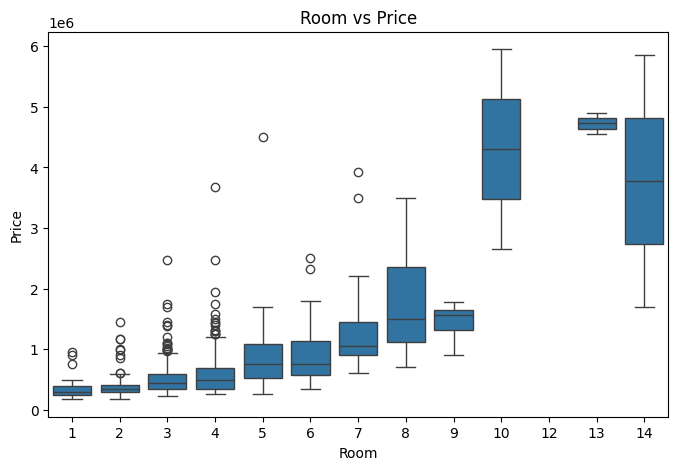

In [ ]:
# Room vs Price

plt.figure(figsize=(8,5))

sns.boxplot(x=df['Room'], y=df['Price'])

plt.title('Room vs Price')

plt.show()


In [ ]:
df.head(5)

,Unnamed: 0,Address,Zip,Price,Area,Room,Lon,Lat
0,1,"Blasiusstraat 8 2, Amsterdam",1091 CR,685000.0,64,3,4.907736,52.356157
1,2,"Kromme Leimuidenstraat 13 H, Amsterdam",1059 EL,475000.0,60,3,4.850476,52.348586
2,3,"Zaaiersweg 11 A, Amsterdam",1097 SM,850000.0,109,4,4.944774,52.343782
3,4,"Tenerifestraat 40, Amsterdam",1060 TH,580000.0,128,6,4.789928,52.343712
4,5,"Winterjanpad 21, Amsterdam",1036 KN,720000.0,138,5,4.902503,52.410538


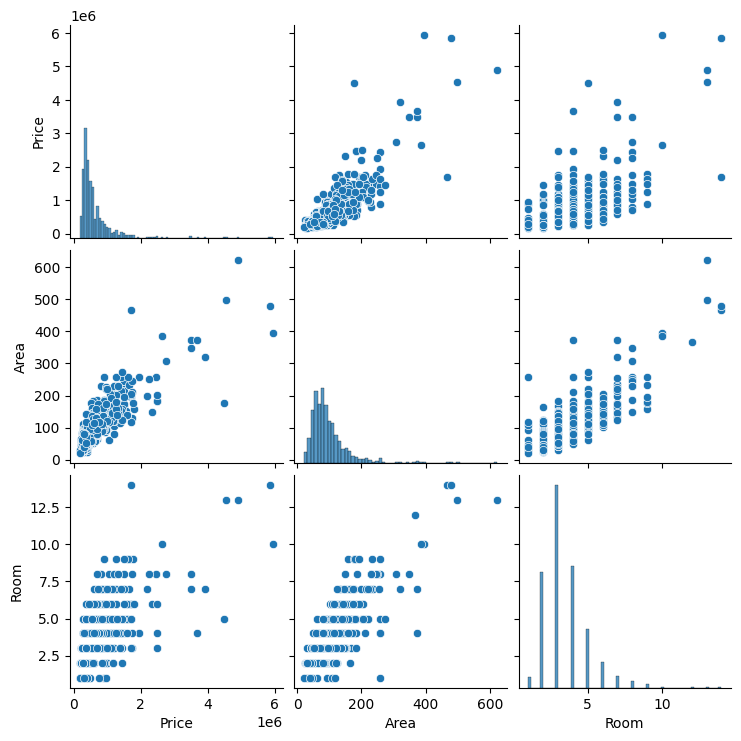

In [ ]:
# Pairplot

sns.pairplot(df[['Price','Area','Room']])

plt.show()



# Feature Engineering


In [ ]:

# Remove Unnecessary Column

df.drop(columns=['Unnamed: 0'], inplace=True)

df.head()


,Address,Zip,Price,Area,Room,Lon,Lat
0,"Blasiusstraat 8 2, Amsterdam",1091 CR,685000.0,64,3,4.907736,52.356157
1,"Kromme Leimuidenstraat 13 H, Amsterdam",1059 EL,475000.0,60,3,4.850476,52.348586
2,"Zaaiersweg 11 A, Amsterdam",1097 SM,850000.0,109,4,4.944774,52.343782
3,"Tenerifestraat 40, Amsterdam",1060 TH,580000.0,128,6,4.789928,52.343712
4,"Winterjanpad 21, Amsterdam",1036 KN,720000.0,138,5,4.902503,52.410538


In [ ]:

# Create City Area Column

df['City_Area'] = df['Address'].apply(
    lambda x: x.split(',')[-1].strip()
)

df.head()


,Address,Zip,Price,Area,Room,Lon,Lat,City_Area
0,"Blasiusstraat 8 2, Amsterdam",1091 CR,685000.0,64,3,4.907736,52.356157,Amsterdam
1,"Kromme Leimuidenstraat 13 H, Amsterdam",1059 EL,475000.0,60,3,4.850476,52.348586,Amsterdam
2,"Zaaiersweg 11 A, Amsterdam",1097 SM,850000.0,109,4,4.944774,52.343782,Amsterdam
3,"Tenerifestraat 40, Amsterdam",1060 TH,580000.0,128,6,4.789928,52.343712,Amsterdam
4,"Winterjanpad 21, Amsterdam",1036 KN,720000.0,138,5,4.902503,52.410538,Amsterdam



# Encoding


In [ ]:

# Label Encoding

le = LabelEncoder()

categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:

    df[col] = le.fit_transform(df[col])

df.head()


,Address,Zip,Price,Area,Room,Lon,Lat,City_Area
0,97,694,685000.0,64,3,4.907736,52.356157,0
1,450,421,475000.0,60,3,4.850476,52.348586,0
2,905,752,850000.0,109,4,4.944774,52.343782,0
3,754,436,580000.0,128,6,4.789928,52.343712,0
4,898,257,720000.0,138,5,4.902503,52.410538,0



# Correlation Analysis


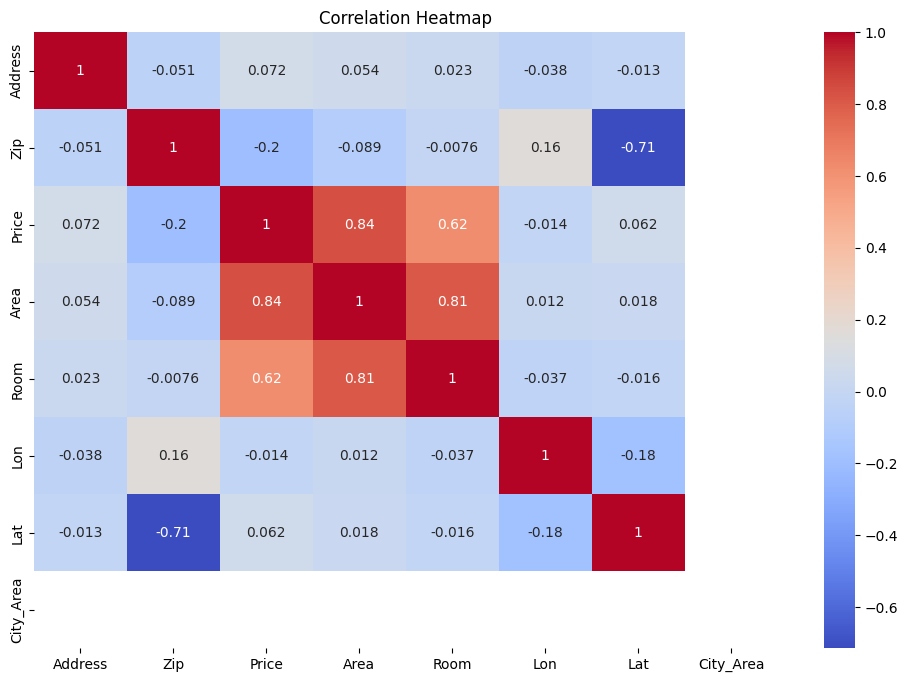

In [ ]:

# Correlation Heatmap

plt.figure(figsize=(12,8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')

plt.show()



# Outlier Detection


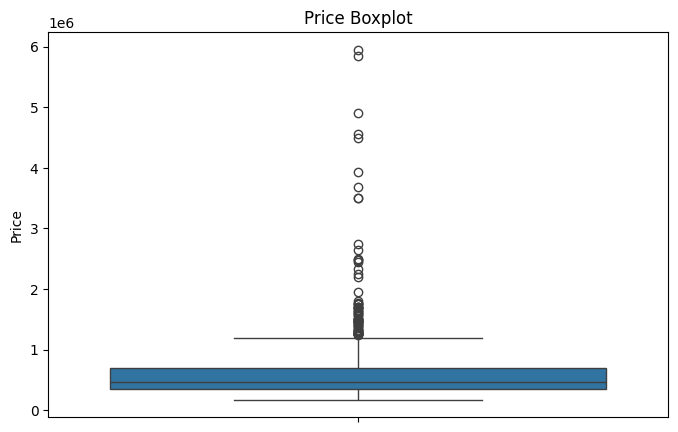

In [ ]:

# Price Boxplot

plt.figure(figsize=(8,5))

sns.boxplot(df['Price'])

plt.title('Price Boxplot')

plt.show()


In [ ]:

# IQR Method

Q1 = df['Price'].quantile(0.25)

Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

df = df[
    (df['Price'] >= lower_limit) &
    (df['Price'] <= upper_limit)
]

df.shape


(849, 8)


# Define Features and Target


In [ ]:

X = df.drop(columns=['Price'])

y = df['Price']



# Train Test Split


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.2,

    random_state=42
)



# Feature Scaling


In [ ]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)


# Linear Regression

In [ ]:

# Train Model

lr = LinearRegression()

lr.fit(X_train, y_train)


LinearRegression()

In [ ]:

# Prediction

y_pred_lr = lr.predict(X_test)


In [ ]:

# Evaluation

mae = mean_absolute_error(y_test, y_pred_lr)

mse = mean_squared_error(y_test, y_pred_lr)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_lr)

print("MAE :", mae)

print("MSE :", mse)

print("RMSE :", rmse)

print("R2 Score :", r2)


MAE : 115387.14656245982
MSE : 19907811813.9003
RMSE : 141095.04532016814
R2 Score : 0.5691703116752176


# Decision Tree Regressor

In [ ]:

# Train Model

dt = DecisionTreeRegressor(random_state=42)

dt.fit(X_train, y_train)


DecisionTreeRegressor(random_state=42)

In [ ]:

# Prediction

y_pred_dt = dt.predict(X_test)


In [ ]:

# Evaluation

mae = mean_absolute_error(y_test, y_pred_dt)

mse = mean_squared_error(y_test, y_pred_dt)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_dt)

print("MAE :", mae)

print("MSE :", mse)

print("RMSE :", rmse)

print("R2 Score :", r2)


MAE : 78275.80588235294
MSE : 13538645419.229412
RMSE : 116355.68494589945
R2 Score : 0.7070069558205458


# Random Forest Regressor

In [ ]:

# Train Model

rf = RandomForestRegressor(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)


RandomForestRegressor(random_state=42)

In [ ]:

# Prediction

y_pred_rf = rf.predict(X_test)


In [ ]:

# Evaluation

mae = mean_absolute_error(y_test, y_pred_rf)

mse = mean_squared_error(y_test, y_pred_rf)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_rf)

print("MAE :", mae)

print("MSE :", mse)

print("RMSE :", rmse)

print("R2 Score :", r2)


MAE : 63832.82635294118
MSE : 7957835714.081914
RMSE : 89206.70218140515
R2 Score : 0.8277825854248904


# KNN Regressor

In [ ]:

# Train Model

knn = KNeighborsRegressor()

knn.fit(X_train, y_train)


KNeighborsRegressor()

In [ ]:

# Prediction

y_pred_knn = knn.predict(X_test)


In [ ]:

# Evaluation

mae = mean_absolute_error(y_test, y_pred_knn)

mse = mean_squared_error(y_test, y_pred_knn)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_knn)

print("MAE :", mae)

print("MSE :", mse)

print("RMSE :", rmse)

print("R2 Score :", r2)


MAE : 80994.71058823529
MSE : 12314388014.181646
RMSE : 110970.2122832143
R2 Score : 0.7335014013767247
